In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.measure import label, regionprops
from skimage.morphology import disk, opening

# 1. Load Image
image_path = 'images/barya.jpg'
image = cv2.imread(image_path)

if image is None:
    raise FileNotFoundError(f"Image not found at {image_path}. Please check your folder structure.")

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

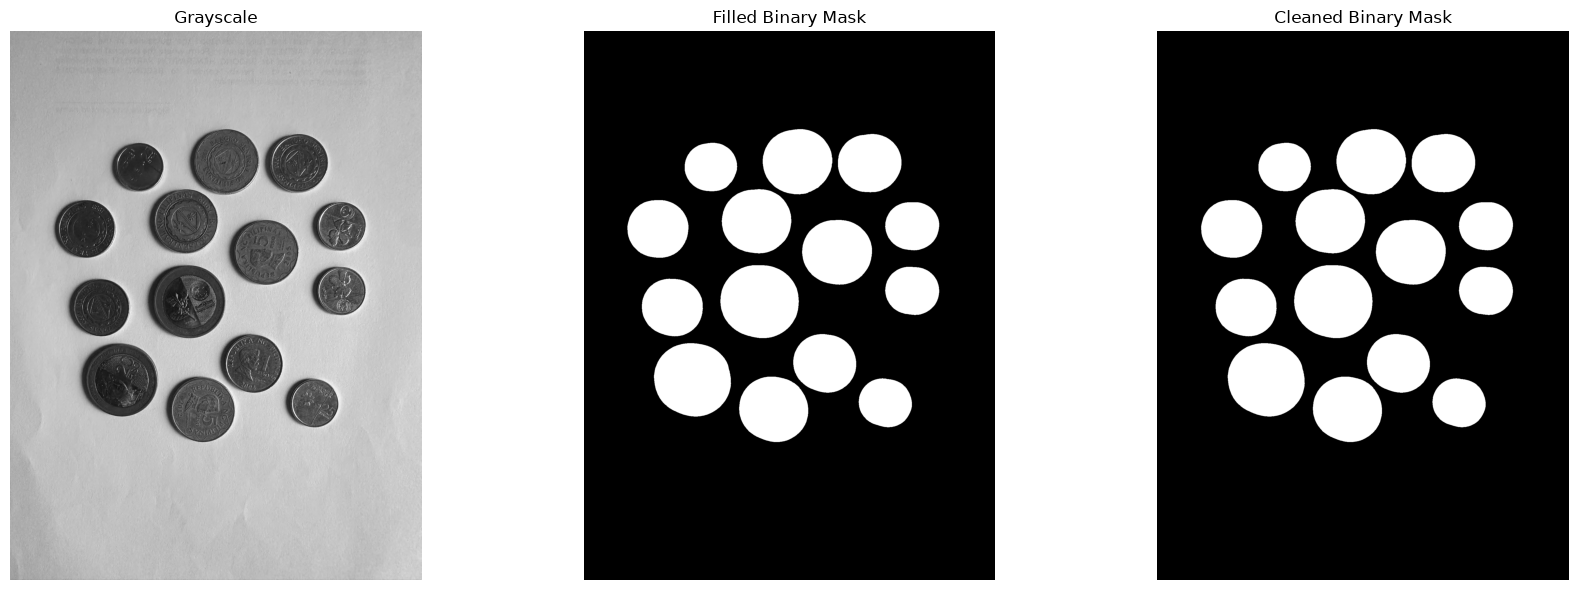

In [2]:
# 2. Preprocessing & Thresholding
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (9, 9), 2)

# Automated Otsu Thresholding
_, binary = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

# Fill holes within coin regions
contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
filled = np.zeros_like(binary)
cv2.drawContours(filled, contours, -1, 255, thickness=cv2.FILLED)

# Morphological Opening to remove small noise
opened = opening(filled > 0, disk(5)).astype(np.uint8)

# Display Preprocessing Steps
fig, axs = plt.subplots(1, 3, figsize=(18, 6))
axs[0].imshow(gray, cmap='gray')
axs[0].set_title("Grayscale")
axs[0].axis("off")

axs[1].imshow(filled, cmap='gray')
axs[1].set_title("Filled Binary Mask")
axs[1].axis("off")

axs[2].imshow(opened, cmap='gray')
axs[2].set_title("Cleaned Binary Mask")
axs[2].axis("off")

plt.tight_layout()
plt.show()

In [3]:
# 3. Label Components & Classification by Relative Area
label_image = label(opened)
regions = regionprops(label_image)

# Filter small noise artifacts
min_area = 500
coin_regions = [r for r in regions if r.area > min_area]

# Classify Coins by Relative Area
cents, one, five, ten, bente = [], [], [], [], []

if coin_regions:
    areas = [r.area for r in coin_regions]
    min_a, max_a = min(areas), max(areas)
    
    for region in coin_regions:
        area = region.area
        # Normalize area relative to smallest and largest detected coins
        norm = (area - min_a) / (max_a - min_a + 1e-5) if max_a != min_a else 0.5
        
        if norm < 0.15:
            cents.append(region)
        elif norm < 0.40:
            one.append(region)
        elif norm < 0.65:
            five.append(region)
        elif norm < 0.85:
            ten.append(region)
        else:
            bente.append(region)

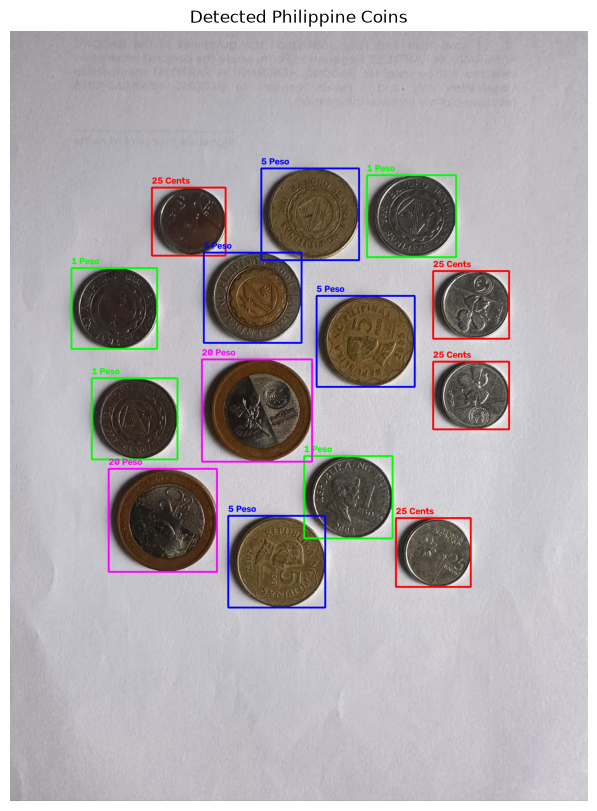

In [4]:
# 4. Draw Annotations on Output Image
output_img = image_rgb.copy()

def draw_labels(regions_list, label_text, color):
    for region in regions_list:
        minr, minc, maxr, maxc = region.bbox
        cv2.rectangle(output_img, (minc, minr), (maxc, maxr), color, 3)
        cv2.putText(
            output_img, label_text, (minc, max(minr - 10, 20)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.8, color, 2, cv2.LINE_AA
        )

# Bounding Box Color Scheme (RGB)
draw_labels(cents, '25 Cents', (255, 0, 0))
draw_labels(one, '1 Peso', (0, 255, 0))
draw_labels(five, '5 Peso', (0, 0, 255))
draw_labels(ten, '10 Peso', (255, 255, 0))
draw_labels(bente, '20 Peso', (255, 0, 255))

# Display Resulting Image
plt.figure(figsize=(12, 10))
plt.imshow(output_img)
plt.title("Detected Philippine Coins")
plt.axis("off")
plt.show()

In [5]:
# 5. Print Summary & Total Value
coin_count = len(cents) + len(one) + len(five) + len(ten) + len(bente)
total_amount = (len(cents) * 0.25) + (len(one) * 1) + (len(five) * 5) + (len(ten) * 10) + (len(bente) * 20)

print("--- COIN DETECTION SUMMARY ---")
print(f"25 Cents : {len(cents)}")
print(f"1 Peso   : {len(one)}")
print(f"5 Peso   : {len(five)}")
print(f"10 Peso  : {len(ten)}")
print(f"20 Peso  : {len(bente)}")
print(f"Total Coin Count     : {coin_count}")
print(f"Total Monetary Value : ₱{total_amount:.2f}")

--- COIN DETECTION SUMMARY ---
25 Cents : 4
1 Peso   : 4
5 Peso   : 4
10 Peso  : 0
20 Peso  : 2
Total Coin Count     : 14
Total Monetary Value : ₱65.00
